# Assignment 1

## Gridworld and Actions

### MDP Definition
#### States (S):
Every cell (row, col) in an R x C grid is a state, EXCEPT cells that
are permanently walled off (not used here, but easy to add).
Obstacle cells and the goal cell ARE states the agent can occupy;
obstacles are just states that give a negative reward and end the
episode, rather than being "unreachable" squares.

#### Actions (A):
UP, DOWN, LEFT, RIGHT  -> move one cell in the corresponding direction.

#### Transition probabilities P(s' | s, a):
- With probability `success_prob` the agent moves in the intended
      direction.
- With probability (1 - success_prob) the agent "slips" and instead
      moves in one of the two directions perpendicular to the intended
      one (split evenly).
- If the resulting move would take the agent off the grid, the agent
      stays in place instead (edge case).
- The goal and every obstacle are TERMINAL states: any action taken
      from them deterministically stays in that same state with 0
      reward (the episode is over, so this is just a formal fix-up so
      the MDP stays well defined).
- Set success_prob=1.0 for a fully deterministic grid world.

#### Reward function R(s, a, s'):
- +1.0  for transitioning INTO the goal state
- -1.0  for transitioning INTO an obstacle state
- -0.01 "living cost" for every other move

In [1]:
import numpy as np
from enum import Enum

In [2]:
class Action(Enum):
    UP = 0
    DOWN = 1
    LEFT = 2
    RIGHT = 3


# (row_delta, col_delta) for each action
ACTION_DELTAS = {
    Action.UP: (-1, 0),
    Action.DOWN: (1, 0),
    Action.LEFT: (0, -1),
    Action.RIGHT: (0, 1),
}

# perpendicular actions used for "slip" transitions
PERPENDICULAR = {
    Action.UP: (Action.LEFT, Action.RIGHT),
    Action.DOWN: (Action.LEFT, Action.RIGHT),
    Action.LEFT: (Action.UP, Action.DOWN),
    Action.RIGHT: (Action.UP, Action.DOWN),
}

In [3]:
class GridWorld:
    def __init__(
        self,
        n_rows,
        n_cols,
        start,
        goal,
        obstacles=None,
        success_prob=1.0,
        step_reward=-0.01,
        goal_reward=1.0,
        obstacle_reward=-1.0,
    ):
        self.n_rows = n_rows
        self.n_cols = n_cols
        self.start = start
        self.goal = goal
        self.obstacles = set(obstacles) if obstacles else set()
        self.success_prob = success_prob
        self.step_reward = step_reward
        self.goal_reward = goal_reward
        self.obstacle_reward = obstacle_reward

        self.actions = list(Action)
        self.states = [
            (r, c) for r in range(n_rows) for c in range(n_cols)
        ]

        self._agent_pos = start

    def is_terminal(self, state):
        return state == self.goal or state in self.obstacles

    def _move(self, state, action):
        """Apply an action to a state, handling grid edges. No stochasticity here."""
        dr, dc = ACTION_DELTAS[action]
        r, c = state
        nr, nc = r + dr, c + dc
        if 0 <= nr < self.n_rows and 0 <= nc < self.n_cols:
            return (nr, nc)
        return state  # off-grid move -> stay in place

    def transition_probs(self, state, action):
        """
        Return a dict {next_state: probability} for taking `action` in `state`.
        """
        if self.is_terminal(state):
            # terminal states are absorbing
            return {state: 1.0}

        probs = {}

        def add(s, p):
            probs[s] = probs.get(s, 0.0) + p

        # intended direction
        add(self._move(state, action), self.success_prob)

        # slip directions
        slip_prob = 1.0 - self.success_prob
        if slip_prob > 0:
            left_a, right_a = PERPENDICULAR[action]
            add(self._move(state, left_a), slip_prob / 2)
            add(self._move(state, right_a), slip_prob / 2)

        return probs

    def reward(self, state, action, next_state):
        if self.is_terminal(state):
            return 0.0
        if next_state == self.goal:
            return self.goal_reward
        if next_state in self.obstacles:
            return self.obstacle_reward
        return self.step_reward

    def reset(self):
        self._agent_pos = self.start
        return self._agent_pos

    def step(self, action):
        """Sample a transition and return (next_state, reward, done)."""
        probs = self.transition_probs(self._agent_pos, action)
        next_states = list(probs.keys())
        p = list(probs.values())
        next_state = next_states[np.random.choice(len(next_states), p=p)]

        r = self.reward(self._agent_pos, action, next_state)
        self._agent_pos = next_state
        done = self.is_terminal(next_state)
        return next_state, r, done

    def render(self):
        grid = ""
        for r in range(self.n_rows):
            row = ""
            for c in range(self.n_cols):
                cell = (r, c)
                if cell == self._agent_pos:
                    row += " A "
                elif cell == self.goal:
                    row += " G "
                elif cell in self.obstacles:
                    row += " X "
                else:
                    row += " . "
            grid += row + "\n"
        print(grid)

## Value Iteration

In [4]:
def value_iteration(env: GridWorld, gamma=0.95, theta=1e-6, max_iters=1000):
    V = {s: 0.0 for s in env.states}

    for _ in range(max_iters):
        delta = 0.0
        new_V = V.copy()

        for s in env.states:
            if env.is_terminal(s):
                continue

            action_values = []
            for a in env.actions:
                probs = env.transition_probs(s, a)
                q_sa = sum(
                    p * (env.reward(s, a, s_next) + gamma * V[s_next])
                    for s_next, p in probs.items()
                )
                action_values.append(q_sa)

            new_V[s] = max(action_values)
            delta = max(delta, abs(new_V[s] - V[s]))

        V = new_V

        if delta < theta:
            break

    policy = extract_policy(env, V, gamma)
    return V, policy


def extract_policy(env: GridWorld, V, gamma=0.95):
    policy = {}
    for s in env.states:
        if env.is_terminal(s):
            policy[s] = None
            continue

        best_a, best_q = None, -float("inf")
        for a in env.actions:
            probs = env.transition_probs(s, a)
            q_sa = sum(
                p * (env.reward(s, a, s_next) + gamma * V[s_next])
                for s_next, p in probs.items()
            )
            if q_sa > best_q:
                best_q, best_a = q_sa, a
        policy[s] = best_a
    return policy


def print_policy(env: GridWorld, policy):
    arrows = {
        Action.UP: "^",
        Action.DOWN: "v",
        Action.LEFT: "<",
        Action.RIGHT: ">",
        None: " ",
    }
    for r in range(env.n_rows):
        row = ""
        for c in range(env.n_cols):
            s = (r, c)
            if s == env.goal:
                row += " G "
            elif s in env.obstacles:
                row += " X "
            else:
                row += f" {arrows[policy[s]]} "
        print(row)


## Main Iteration

In [5]:
env = GridWorld(
    n_rows=4,
    n_cols=4,
    start=(3, 0),
    goal=(0, 3),
    obstacles=[(1, 1), (2, 2)],
    success_prob=1.0,  # 0.8 intended move, 0.2 split between the two slip directions
    step_reward=-0.01,
    goal_reward=1.0,
    obstacle_reward=-1.0,
)

V, policy = value_iteration(env, gamma=0.95)

print("Learned policy (^ v < > = greedy action, G = goal, X = obstacle):")
print_policy(env, policy)
print("\nState values:")
for r in range(env.n_rows): print(["{:6.2f}".format(V[(r, c)]) for c in range(env.n_cols)])
print("\nRunning one episode with the learned policy:")

state = env.reset()
env.render()
done = False
total_reward = 0.0
steps = 0
while not done and steps < 50:
    action = policy[state]
    state, reward, done = env.step(action)
    total_reward += reward
    steps += 1
    env.render()

print(f"Episode finished in {steps} steps, total reward = {total_reward:.2f}")

Learned policy (^ v < > = greedy action, G = goal, X = obstacle):
 >  >  >  G 
 ^  X  ^  ^ 
 ^  v  X  ^ 
 ^  >  >  ^ 

State values:
['  0.88', '  0.94', '  1.00', '  0.00']
['  0.83', '  0.00', '  0.94', '  1.00']
['  0.78', '  0.73', '  0.00', '  0.94']
['  0.73', '  0.78', '  0.83', '  0.88']

Running one episode with the learned policy:
 .  .  .  G 
 .  X  .  . 
 .  .  X  . 
 A  .  .  . 

 .  .  .  G 
 .  X  .  . 
 A  .  X  . 
 .  .  .  . 

 .  .  .  G 
 A  X  .  . 
 .  .  X  . 
 .  .  .  . 

 A  .  .  G 
 .  X  .  . 
 .  .  X  . 
 .  .  .  . 

 .  A  .  G 
 .  X  .  . 
 .  .  X  . 
 .  .  .  . 

 .  .  A  G 
 .  X  .  . 
 .  .  X  . 
 .  .  .  . 

 .  .  .  A 
 .  X  .  . 
 .  .  X  . 
 .  .  .  . 

Episode finished in 6 steps, total reward = 0.95


# Visualization

1. A clear and informative visualization of the grid world, including obstacles, starting state, and goal state.
2. A visualization of the computed value function for each state.
3. A visualization of the optimal policy, indicating the best action for each state.

In [6]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from gridworld import GridWorld, Action
from matplotlib.colors import ListedColormap

In [7]:
sns.set_theme(style="white", font_scale=1.1)
ACTION_ARROWS = {
    Action.UP: "↑",
    Action.DOWN: "↓",
    Action.LEFT: "←",
    Action.RIGHT: "→",
}

## Plot Gridworld

In [8]:
def plot_gridworld(env):
    grid = np.zeros((env.n_rows, env.n_cols))
    for r, c in env.obstacles: grid[r, c] = 1

    sr, sc = env.start
    grid[sr, sc] = 2
    gr, gc = env.goal
    grid[gr, gc] = 3

    cmap = ListedColormap(["white", "black", "#5DADE2", "#58D68D"])
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(grid, cmap=cmap, vmin=0, vmax=3, cbar=False, linewidths=0.75, linecolor="black",
        square=True, ax=ax, xticklabels=False, yticklabels=False)

    # Obstacles
    for r, c in env.obstacles:
        ax.text(c + 0.5, r + 0.5, "Obstacle", ha="center", va="center", color="white", fontsize=10, fontweight="bold")

    # Start
    ax.text(sc + 0.5, sr + 0.5, "Start", ha="center", va="center", color="black", fontsize=11, fontweight="bold")

    # Goal
    ax.text(gc + 0.5, gr + 0.5, "Goal", ha="center", va="center", color="black", fontsize=11, fontweight="bold")

    ax.set_title("Grid World Environment", fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    plt.tight_layout()
    plt.show()

## Plot Computed Value Function

In [9]:
def plot_value_function(env, V):
    values = np.zeros((env.n_rows, env.n_cols))

    for r in range(env.n_rows):
        for c in range(env.n_cols):
            values[r, c] = V[(r, c)]

    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(values, cmap="Blues", linewidths=2, linecolor="white", square=True,
        cbar=True, cbar_kws={"label": "State value V(s)"}, xticklabels=False, yticklabels=False, ax=ax)

    # State values
    for r in range(env.n_rows):
        for c in range(env.n_cols):
            state = (r, c)

            if state in env.obstacles:
                ax.text(c + 0.5, r + 0.5, "X", ha="center", va="center", color="black", fontsize=18, fontweight="bold", zorder=5)
            elif state == env.goal:
                ax.text(c + 0.5, r + 0.5, "Goal", ha="center", va="center", color="black", fontsize=11, fontweight="bold", zorder=5)
            else:
                ax.text(c + 0.5, r + 0.5, f"{V[state]:.3f}", ha="center", va="center", color="black", fontsize=12, fontweight="bold", zorder=5)

    # Start
    sr, sc = env.start
    ax.text(sc + 0.5, sr + 0.18, "Start", ha="center", va="center", fontsize=9, fontweight="bold", color="black", zorder=6)

    ax.set_title("Optimal State-Value Function", fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    plt.tight_layout()
    plt.show()

## Plot Optimal Policy Action

In [10]:
def plot_policy(env, policy, V=None):
    fig, ax = plt.subplots(figsize=(7, 6))

    values = np.zeros((env.n_rows, env.n_cols))
    for r in range(env.n_rows):
        for c in range(env.n_cols):
            values[r, c] = V[(r, c)]

    sns.heatmap(values, cmap="Blues", linewidths=2, linecolor="white", square=True, cbar=True,
        cbar_kws={"label": "State value V(s)"}, xticklabels=False, yticklabels=False, ax=ax, alpha=0.65)

    # Policy arrows
    for r in range(env.n_rows):
        for c in range(env.n_cols):
            state = (r, c)

            # Obstacles
            if state in env.obstacles:
                ax.text(c + 0.5, r + 0.5, "X", ha="center", va="center", color="black", fontsize=18, fontweight="bold", zorder=5)
                continue

            # Goal
            if state == env.goal:
                ax.text(c + 0.5, r + 0.5, "Goal", ha="center", va="center", fontsize=12, fontweight="bold", color="black", zorder=5)
                continue

            # Policy arrow
            action = policy[state]
            if action is not None:
                ax.text(c + 0.5, r + 0.53, ACTION_ARROWS[action], ha="center", va="center", fontsize=28, fontweight="bold", color="black", zorder=6)

    # Start state
    sr, sc = env.start
    ax.text(sc + 0.5, sr + 0.18, "Start", ha="center", va="center", fontsize=10, fontweight="bold", color="black", zorder=8)

    ax.set_title("Optimal Policy", fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    plt.tight_layout()
    plt.show()

## Main Iteration and Plots

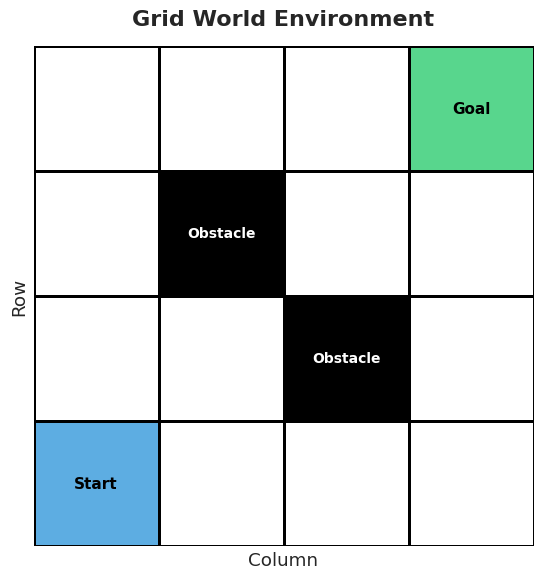

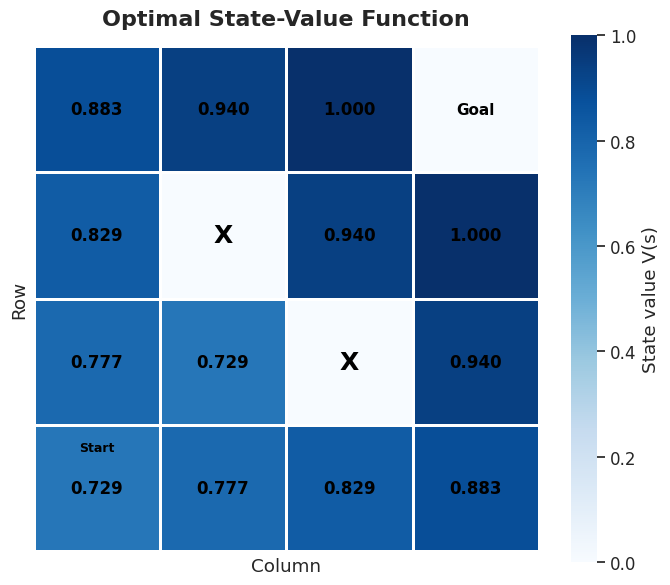

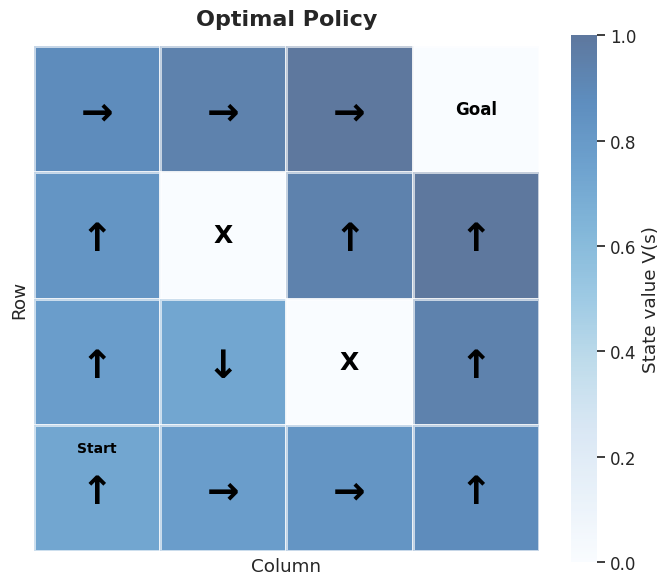

In [11]:
env = GridWorld(
    n_rows=4,
    n_cols=4,
    start=(3, 0),
    goal=(0, 3),
    obstacles=[(1, 1), (2, 2)],
    success_prob=1.0,  # 0.8 intended move, 0.2 split between the two slip directions
    step_reward=-0.01,
    goal_reward=1.0,
    obstacle_reward=-1.0,
)

V, policy = value_iteration(env, gamma=0.95)
plot_gridworld(env)
plot_value_function(env, V)
plot_policy(env, policy, V)